# Building Heights: Global Building Atlas vs Cadastral
-Compare GBA and cadastral height coverage for Bologna
- then produce a gap-filled final dataset using cadastral as primary and GBA as fallback.

**Structure:**
1. Load & clean data
2. Geometry matching (spatial join)
3. Height comparison & metrics
4. Coverage summary (GBA only / cadastral only)
5. Gap-filling


In [1]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

## 1. Load & Clean Data
- Filter buildings with area > 5 m² to remove shelters, garages, tiny structures
- Clip both datasets to Bologna municipal boundary

In [2]:
bologna_boundary = gpd.read_file("data/bologna_boundary.gpkg", driver='GPKG').to_crs("EPSG:32632")
global_atlas = gpd.read_file("data/global_atlas_height.geojson").to_crs("EPSG:32632")
cadastral = gpd.read_file("data/catastral_map_with_heights.geojson").to_crs("EPSG:32632")

# ── GBA: clip + filter small footprints ────────────────────────────────────
global_atlas = gpd.clip(global_atlas, bologna_boundary)
global_atlas["area_m2"] = global_atlas.geometry.area
global_atlas  = global_atlas[global_atlas["area_m2"] > 5].copy()
global_atlas["height_filtered"] = global_atlas["height"]  # GBA always has height

# ── Cadastral: clip + filter small footprints + compute height ──────────────
cadastral_clipped = gpd.clip(cadastral, bologna_boundary)
cadastral_clipped["area_m2"] = cadastral_clipped.geometry.area
cadastral_clipped = cadastral_clipped[cadastral_clipped["area_m2"] > 5].copy()
cadastral_clipped["height"]  = cadastral_clipped["altezza_gr"].fillna(cadastral_clipped["quota_gron"] - cadastral_clipped["quota_pied"])
cadastral_clipped["height_filtered"] = cadastral_clipped["height"].where(cadastral_clipped["height"] > 0, 0)

#sum
print("1. DATA SUMMARY")
print(f"GBA = Total buildings : {len(global_atlas):>8,}")
print(f"  Height > 0 : {(global_atlas['height_filtered'] > 0).sum():>8,}")
print(f" Zero/missing : {(global_atlas['height_filtered'] <= 0).sum():>8,}")
print(f"CADASTRAL = Total buildings : {len(cadastral_clipped):>8,}")
print(f"Height > 0 : {(cadastral_clipped['height_filtered'] > 0).sum():>8,}")
print(f" Zero/missing: {(cadastral_clipped['height_filtered'] <= 0).sum():>8,}")

/opt/anaconda3/lib/python3.11/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(


1. DATA SUMMARY
  GBA  — Total buildings :   53,365
         Height > 0      :   53,365
         Zero/missing    :        0

  CAD  — Total buildings :   65,058
         Height > 0      :   54,372
         Zero/missing    :   10,686


## 2. Geometry Matching
Spatial join GBA ↔ cadastral by intersection. For buildings matched to multiple candidates, keep the one with the largest overlap area.

In [3]:
left = global_atlas[["geometry", "height_filtered"]].rename(columns={"height_filtered": "height_left"})
right = cadastral_clipped[["geometry", "height_filtered"]].rename(columns={"height_filtered": "height_right"})

joined_all = gpd.sjoin(left, right, how="inner", predicate="intersects")

# Compute overlap area and keep best match per GBA building
right_geoms = right.geometry
joined_all["overlap_area"] = joined_all.apply(
    lambda row: row.geometry.intersection(right_geoms.loc[row["index_right"]]).area,
    axis=1
)
joined_all = joined_all.sort_values("overlap_area", ascending=False)
joined_all = joined_all[~joined_all.index.duplicated(keep="first")]

print(f"Geometrically matched buildings: {len(joined_all):,}")

Geometrically matched buildings: 50,974


## 3. Height Comparison
Compare heights only for buildings where **both** datasets have height > 0.

In [4]:
# Filter to buildings with height in both datasets
joined_heights = joined_all[
    (joined_all["height_left"] > 0) &
    (joined_all["height_right"] > 0)
].copy()

joined_heights["height_diff"]  = (joined_heights["height_left"] - joined_heights["height_right"]).abs()
joined_heights["signed_diff"]  =  joined_heights["height_left"] - joined_heights["height_right"]

# Threshold sensitivity
thresholds = [1, 2, 3, 5, 8, 10]
mean_bias      = joined_heights["signed_diff"].mean()
threshold_75   = joined_heights["height_diff"].quantile(0.75)
median         = joined_heights["height_diff"].median()
mad            = np.median(np.abs(joined_heights["height_diff"] - median))
threshold_mad  = median + 2 * mad

print("3. HEIGHT COMPARISON")
print(f"Geometrically matched : {len(joined_all):>8,}")
print(f"Height > 0 in both datasets : {len(joined_heights):>8,}")
print(f"Missing height in one or both: {len(joined_all) - len(joined_heights):>8,}")
print("Threshold sensitivity:")
for t in thresholds:
    n   = (joined_heights["height_diff"] <= t).sum()
    pct = (joined_heights["height_diff"] <= t).mean() * 100
    print(f"    ±{t:>2} m => {n:>6,}  ({pct:.1f}%)")

print(f"Mean signed bias (GBA − cadastral): {mean_bias:+.2f} m")
print(f"75th percentile threshold   : {threshold_75:.2f} m")
print(f"Robust MAD threshold  : {threshold_mad:.2f} m")
print(f" stats:")
print(joined_heights["height_diff"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).round(2).to_string())

3. HEIGHT COMPARISON
Geometrically matched :   50,974
Height > 0 in both datasets :   48,832
Missing height in one or both:    2,142
Threshold sensitivity:
    ± 1 m =>  8,197  (16.8%)
    ± 2 m => 15,964  (32.7%)
    ± 3 m => 22,809  (46.7%)
    ± 5 m => 33,057  (67.7%)
    ± 8 m => 41,687  (85.4%)
    ±10 m => 44,359  (90.8%)
Mean signed bias (GBA − cadastral): -2.51 m
75th percentile threshold   : 5.93 m
Robust MAD threshold  : 7.37 m
 stats:
count    48832.00
mean         4.46
std          4.42
min          0.00
10%          0.58
25%          1.50
50%          3.27
75%          5.93
90%          9.61
95%         13.05
max         80.10


## 4. Coverage Summary: GBA only / Cadastral only

In [14]:
# GBA buildings with NO cadastral match
matched_gba   = gpd.sjoin(
    global_atlas[["geometry", "height_filtered"]],
    cadastral_clipped[["geometry"]],
    how="left", predicate="intersects"
)
unmatched_idx     = matched_gba[matched_gba["index_right"].isna()].index.unique()
gba_no_cadastral  = global_atlas.loc[unmatched_idx].copy()
gba_no_cadastral  = gba_no_cadastral[gba_no_cadastral["height_filtered"] > 0]

# Cadastral buildings with NO GBA match
matched_cadastral  = gpd.sjoin(
    cadastral_clipped[["geometry"]],
    global_atlas[["geometry"]],
    how="left", predicate="intersects"
)
cadastral_only_idx = matched_cadastral[matched_cadastral["index_right"].isna()].index.unique()

n_matched        = matched_gba[matched_gba["index_right"].notna()].index.nunique()
n_gba_only       = len(gba_no_cadastral)
n_cadastral_only = len(cadastral_only_idx)

# Height-specific gaps (matched geometrically but height missing in one)
gba_height_not_in_cad = joined_all[
    (joined_all["height_left"] > 0) & (joined_all["height_right"] <= 0)
]
cad_height_not_in_gba = joined_all[
    (joined_all["height_right"] > 0) & (joined_all["height_left"] <= 0)
]

# Metrics
total_gba = len(global_atlas)
total_cadastral = len(cadastral_clipped)
precision = n_matched / total_gba
recall  = n_matched / total_cadastral
f1 = 2 * precision * recall / (precision + recall)
jaccard   = n_matched / (total_gba + total_cadastral - n_matched)

# GBA buildings that have at least one cadastral match
n_gba_matched       = matched_gba[matched_gba["index_right"].notna()].index.nunique()

# Cadastral buildings that have at least one GBA match  
n_cadastral_matched = matched_cadastral[matched_cadastral["index_right"].notna()].index.nunique()

n_gba_only          = total_gba - n_gba_matched
n_cadastral_only    = total_cadastral - n_cadastral_matched

print(f"  Total GBA buildings              : {total_gba:>8,}")
print(f"  GBA matched                      : {n_gba_matched:>8,}")
print(f"  GBA only                         : {n_gba_only:>8,}")  # should = 2,391
print(f"  Check: {n_gba_matched} + {n_gba_only} = {n_gba_matched + n_gba_only:,} ✓")
print()
print(f"  Total cadastral buildings        : {total_cadastral:>8,}")
print(f"  Cadastral matched                : {n_cadastral_matched:>8,}")
print(f"  Cadastral only                   : {n_cadastral_only:>8,}")
print(f"  Check: {n_cadastral_matched} + {n_cadastral_only} = {n_cadastral_matched + n_cadastral_only:,} ✓")



  Total GBA buildings              :   53,365
  GBA matched                      :   50,974
  GBA only                         :    2,391
  Check: 50974 + 2391 = 53,365 ✓

  Total cadastral buildings        :   65,058
  Cadastral matched                :   57,817
  Cadastral only                   :    7,241
  Check: 57817 + 7241 = 65,058 ✓


## 5. Gap-Filling
Strategy:
- **Case A** — cadastral building exists but height ≤ 0 → fill from nearest GBA building (2 m buffer)
- **Case B** — GBA building has no cadastral counterpart at all → append to final dataset

Note: mean signed bias is −2.51 m (GBA underestimates vs cadastral). Using cadastral as primary partially corrects for this.

In [15]:
# ── Base: cadastral ─────────────────────────────────────────────────────────
bologna_buildings_final = cadastral_clipped[["geometry", "height_filtered"]].copy()
bologna_buildings_final = bologna_buildings_final.rename(columns={"height_filtered": "height"})
bologna_buildings_final["source"] = "cadastral"

n_cad_base     = len(bologna_buildings_final)
n_cad_has_height = (bologna_buildings_final["height"] > 0).sum()
n_needs_fill   = (bologna_buildings_final["height"] <= 0).sum()

# ── Case A: fill missing heights from GBA ───────────────────────────────────
needs_fill_mask  = bologna_buildings_final["height"] <= 0
needs_fill       = bologna_buildings_final[needs_fill_mask].copy()
needs_fill_buf   = needs_fill.copy()
needs_fill_buf["geometry"] = needs_fill_buf.geometry.buffer(2)

gba_valid   = global_atlas[global_atlas["height_filtered"] > 0][["geometry", "height_filtered"]].copy()
joined_fill = gpd.sjoin(needs_fill_buf[["geometry"]], gba_valid, how="left", predicate="intersects")
best_fill   = joined_fill.dropna(subset=["height_filtered"]).groupby(level=0)["height_filtered"].first()

bologna_buildings_final.loc[best_fill.index, "height"]  = best_fill.values
bologna_buildings_final.loc[best_fill.index, "source"]  = "cadastral_gba_fill"

n_filled       = len(best_fill)
n_still_missing = (bologna_buildings_final["height"] <= 0).sum()

# ── Case B: append GBA buildings absent from cadastral entirely ─────────────
gba_extra = gba_no_cadastral[["geometry", "height_filtered"]].rename(
    columns={"height_filtered": "height"}
).copy()
gba_extra["source"] = "gba_only"

n_gba_appended = len(gba_extra)

# ── Concatenate ─────────────────────────────────────────────────────────────
bologna_buildings_final = pd.concat([bologna_buildings_final, gba_extra], ignore_index=True)
bologna_buildings_final = gpd.GeoDataFrame(bologna_buildings_final, geometry="geometry", crs="EPSG:32632")

## 6. Final Dataset Summary

In [16]:
src = bologna_buildings_final.groupby("source")["height"].agg(["count", "mean"]).round(1)
total_final = len(bologna_buildings_final)

print("5. CADASTRAL (before gap-fill)")
print(f"Total buildings : {n_cad_base:>8,}")
print(f"Height > 0: {n_cad_has_height:>8,}")
print(f"Zero/missing height : {n_needs_fill:>8,}")

print(f"Height filled with GBA : {n_filled:>8,}")
print(f"  Cadastral needing fill           : {n_needs_fill:>8,}")  
print(f"  Filled via GBA (2m buffer)       : {n_filled:>8,}")
print(f"  Still missing after fill         : {n_still_missing:>8,}")

print("6. FINAL DATASET")
print("=" * 45)

cad_with_height  = ((bologna_buildings_final["source"] == "cadastral") & 
                    (bologna_buildings_final["height"] > 0)).sum()
gba_fill_count   = (bologna_buildings_final["source"] == "cadastral_gba_fill").sum()
gba_only_count   = (bologna_buildings_final["source"] == "gba_only").sum()

print(f"  Heights from cadastral           : {cad_with_height:>8,}")
print(f"  Heights from GBA (gap-fill)      : {gba_fill_count:>8,}")
print(f"  Buildings solely from GBA        : {gba_only_count:>8,}")
print(f"  ─────────────────────────────────")
print(f"  Total buildings                  : {total_final:>8,}")
print(f"  With height > 0                  : {(bologna_buildings_final['height'] > 0).sum():>8,}")
print(f"  Still zero/missing               : {(bologna_buildings_final['height'] <= 0).sum():>8,}")

# Save
bologna_buildings_final.to_file("data/bologna_buildings_final.gpkg", driver="GPKG")
print("\nSaved: data/bologna_buildings_final.gpkg")

5. CADASTRAL (before gap-fill)
Total buildings :   65,058
Height > 0:   54,372
Zero/missing height :   10,686
Height filled with GBA :    6,881
  Cadastral needing fill           :   10,686
  Filled via GBA (2m buffer)       :    6,881
  Still missing after fill         :    3,805
6. FINAL DATASET
  Heights from cadastral           :   54,372
  Heights from GBA (gap-fill)      :    6,881
  Buildings solely from GBA        :    2,391
  ─────────────────────────────────
  Total buildings                  :   67,449
  With height > 0                  :   63,644
  Still zero/missing               :    3,805

Saved: data/bologna_buildings_final.gpkg


## 7. Export QGIS Comparison Layers

In [8]:
global_atlas["match_status"]    = "matched"
global_atlas.loc[gba_no_cadastral.index, "match_status"] = "gba_only"

cadastral_clipped["match_status"] = "matched"
cadastral_clipped.loc[cadastral_only_idx, "match_status"] = "cadastral_only"

out_path = "building_comparison.gpkg"
global_atlas[["geometry", "height_filtered", "match_status"]].to_file(out_path, layer="gba_buildings",       driver="GPKG")
cadastral_clipped[["geometry", "height_filtered", "match_status"]].to_file(out_path, layer="cadastral_buildings", driver="GPKG")
print(f"QGIS layers saved to {out_path}")
print("  Layers: gba_buildings, cadastral_buildings")
print("  Style by 'match_status' column: matched / gba_only / cadastral_only")

QGIS layers saved to building_comparison.gpkg
  Layers: gba_buildings, cadastral_buildings
  Style by 'match_status' column: matched / gba_only / cadastral_only


## 8. Plots

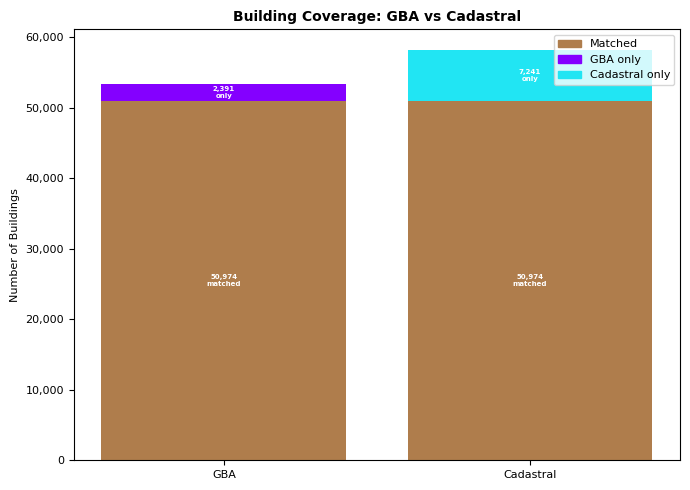

In [19]:
# ── Plot 1: Building coverage bar chart ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

categories     = ["GBA", "Cadastral"]
matched_counts = [n_matched, n_matched]
only_counts    = [n_gba_only, n_cadastral_only]
only_colors    = ["#8400FF", "#21E5F3"]

ax.bar(categories, matched_counts, color="#AF7D4C")
ax.bar(categories, only_counts, bottom=matched_counts, color=only_colors)

for i, (m, u) in enumerate(zip(matched_counts, only_counts)):
    ax.text(i, m / 2,     f"{m:,}\nmatched", ha="center", va="center", color="white", fontsize=5, fontweight="bold")
    ax.text(i, m + u / 2, f"{u:,}\nonly",    ha="center", va="center", color="white", fontsize=5, fontweight="bold")

ax.legend(handles=[
    mpatches.Patch(color="#AF7D4C", label="Matched"),
    mpatches.Patch(color="#8400FF", label="GBA only"),
    mpatches.Patch(color="#21E5F3", label="Cadastral only")
], fontsize=8)
ax.set_title("Building Coverage: GBA vs Cadastral", fontweight="bold", fontsize=10)
ax.set_ylabel("Number of Buildings", fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.savefig("plot_building_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

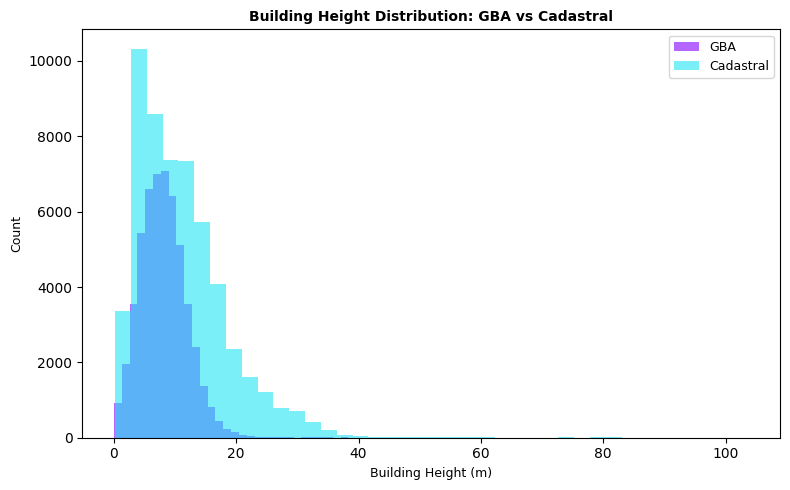

In [10]:
# ── Plot 2: Height distribution histogram ───────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(global_atlas[global_atlas["height_filtered"] > 0]["height_filtered"],
        bins=40, alpha=0.6, color="#8400FF", label="GBA")
ax.hist(cadastral_clipped[cadastral_clipped["height_filtered"] > 0]["height_filtered"],
        bins=40, alpha=0.6, color="#21E5F3", label="Cadastral")

ax.set_xlabel("Building Height (m)", fontsize=9)
ax.set_ylabel("Count", fontsize=9)
ax.set_title("Building Height Distribution: GBA vs Cadastral", fontweight="bold", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("plot_height_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

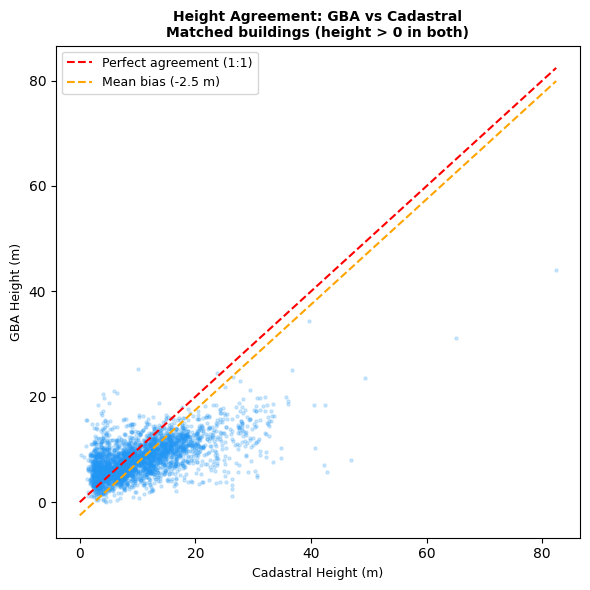

In [11]:
# ── Plot 3: Height scatter (matched buildings) ───────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
sample = joined_heights.sample(min(3000, len(joined_heights)), random_state=42)

ax.scatter(sample["height_right"], sample["height_left"],
           alpha=0.2, s=5, color="#2196F3")

max_h = max(sample["height_right"].max(), sample["height_left"].max())
bias  = sample["signed_diff"].mean()

ax.plot([0, max_h], [0, max_h],         color="red",    linewidth=1.5, linestyle="--", label="Perfect agreement (1:1)")
ax.plot([0, max_h], [bias, max_h+bias], color="orange", linewidth=1.5, linestyle="--", label=f"Mean bias ({bias:+.1f} m)")

ax.set_xlabel("Cadastral Height (m)", fontsize=9)
ax.set_ylabel("GBA Height (m)", fontsize=9)
ax.set_title("Height Agreement: GBA vs Cadastral\nMatched buildings (height > 0 in both)",
             fontweight="bold", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("plot_height_scatter.png", dpi=150, bbox_inches="tight")
plt.show()